# Bank Customer Churn: Exploratory Analysis & Baseline Prediction

**Pet project | Data Science | Python, Pandas, Seaborn, Scikit-learn**

## Project overview

Customer churn is an important business problem for banks: when customers leave, the bank may lose future revenue and opportunities to build long-term relationships. In this project, I explore a public bank-customer dataset, look for patterns associated with churn, and build simple baseline models to estimate which customers are more likely to leave.

**Main questions**
- What does the customer base and churn distribution look like?
- Which customer characteristics are associated with a higher churn rate?
- How do feature transformation, similarity measures, feature selection, PCA, kernels, and outlier methods work on this dataset?
- Can baseline classification models distinguish customers who left from those who stayed?

## Dataset

- **Source:** [Churn for Bank Customers — Kaggle](https://www.kaggle.com/datasets/mathchi/churn-for-bank-customers)
- **File:** `churn.csv`
- **Rows:** 10,000
- **Target:** `Exited` — `1` means the customer left; `0` means the customer stayed.
- **Features used:** 10 (six numeric and four categorical/binary).
- `RowNumber`, `CustomerId`, and `Surname` are excluded from model features. `RowNumber` is retained only as a row identifier in the exploratory analysis.

## Workflow

1. Load the data and check its basic quality.
2. Explore churn distribution and selected customer segments.
3. Apply data-mining techniques to understand customer attributes.
4. Compare simple churn-classification baselines on a held-out test set.
5. Summarize findings and limitations.

> **Scope note:** this dataset supports churn analysis and a basic churn-risk model. It does not contain campaign exposure, offer acceptance, or treatment/outcome history, so it is not sufficient to train or evaluate a Next Best Offer / uplift model.

## Environment

The notebook uses Python libraries: `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`, and `kagglehub`. Install missing packages with `%pip install numpy pandas matplotlib seaborn scikit-learn kagglehub`.


## 1. Setup and data loading

The dataset is downloaded with `kagglehub`. The feature lists are defined once and reused in the analysis and modelling sections.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif, chi2
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    ConfusionMatrixDisplay, classification_report
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import pairwise_distances
from sklearn.metrics.pairwise import cosine_similarity, linear_kernel, rbf_kernel

sns.set_theme(style="whitegrid", context="notebook")
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mathchi/churn-for-bank-customers")

print("Path to dataset files:", path)

c:\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\damir\.cache\kagglehub\datasets\mathchi\churn-for-bank-customers\versions\1


In [2]:
import os
df = pd.read_csv(os.path.join(path, "churn.csv"))


num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
cat_cols = ["Geography", "Gender", "HasCrCard", "IsActiveMember"]
target = "Exited"

In [3]:
print("Dataset shape:", df.shape)

Dataset shape: (10000, 14)


In [4]:
print("Missing values:", int(df.isna().sum().sum()))

Missing values: 0


In [5]:
display(df.head())

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### First look at churn

Before exploring individual features, I check the target distribution. This gives a baseline view of how common customer churn is and whether the target classes are balanced.


Overall churn rate: 20.4%


,Customers,Share
Exited,,
Stayed (0),7963,79.6%
Exited (1),2037,20.4%


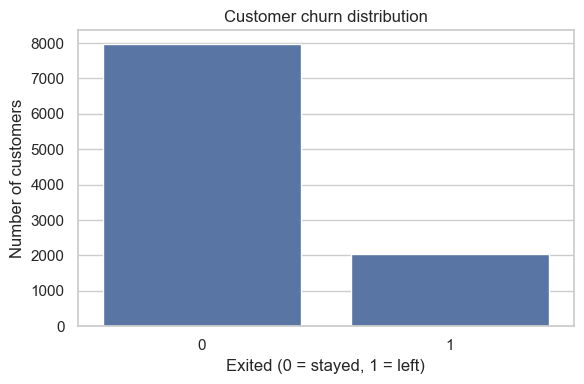

In [6]:
target_counts = df[target].value_counts().sort_index()
churn_rate = df[target].mean()

print(f"Overall churn rate: {churn_rate:.1%}")
display(pd.DataFrame({
    "Customers": target_counts,
    "Share": (target_counts / len(df)).map(lambda value: f"{value:.1%}")
}).rename(index={0: "Stayed (0)", 1: "Exited (1)"}))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=target)
plt.title("Customer churn distribution")
plt.xlabel("Exited (0 = stayed, 1 = left)")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()


### Churn rate across selected segments

I compare churn rates by geography and activity status. These are descriptive comparisons: they show where churn is more common in this dataset, but they do not prove that a particular characteristic causes churn.


,Customers,Churn_rate
Geography,,
Germany,2509,32.4%
Spain,2477,16.7%
France,5014,16.2%


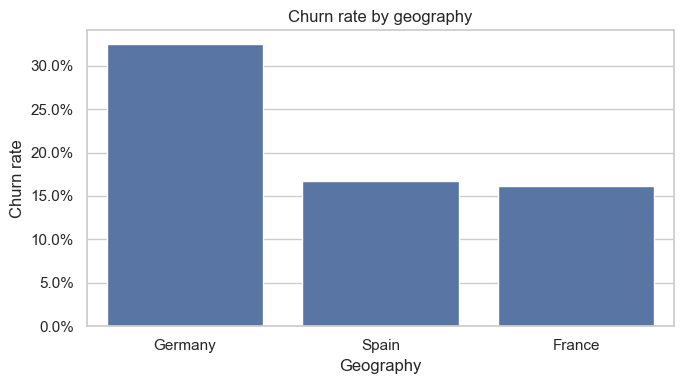

,Customers,Churn_rate
IsActiveMember,,
Inactive,4849,26.9%
Active,5151,14.3%


In [7]:
geography_churn = (
    df.groupby("Geography")[target]
      .agg(Customers="size", Churn_rate="mean")
      .sort_values("Churn_rate", ascending=False)
)
display(geography_churn.style.format({"Churn_rate": "{:.1%}"}))

plt.figure(figsize=(7, 4))
sns.barplot(data=geography_churn.reset_index(), x="Geography", y="Churn_rate")
plt.title("Churn rate by geography")
plt.xlabel("Geography")
plt.ylabel("Churn rate")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.show()

activity_churn = (
    df.groupby("IsActiveMember")[target]
      .agg(Customers="size", Churn_rate="mean")
      .rename(index={0: "Inactive", 1: "Active"})
)
display(activity_churn.style.format({"Churn_rate": "{:.1%}"}))


## 2. Exploratory Data Analysis and Data Mining

### Task 1. Customer age distribution and outliers

I use `Age` for the histogram, box plot, and IQR outlier check. The scatter plot compares `Age` and `Balance`.


In [8]:
age = df["Age"]
q1 = age.quantile(0.25)
q3 = age.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

age_outliers = df.loc[(age < lower) | (age > upper), ["RowNumber", "Age"]]

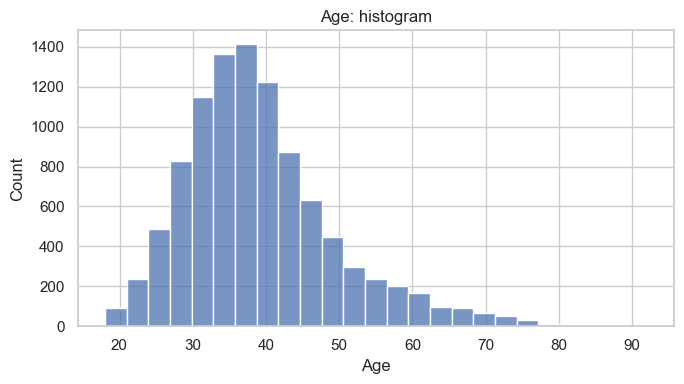

In [9]:
plt.figure(figsize=(7, 4))
sns.histplot(age, bins=25)
plt.title("Age: histogram")
plt.tight_layout()
plt.show()

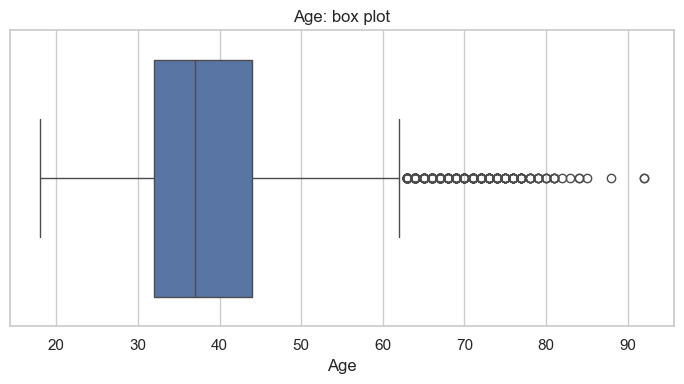

In [10]:
plt.figure(figsize=(7, 4))
sns.boxplot(x=age)
plt.title("Age: box plot")
plt.tight_layout()
plt.show()

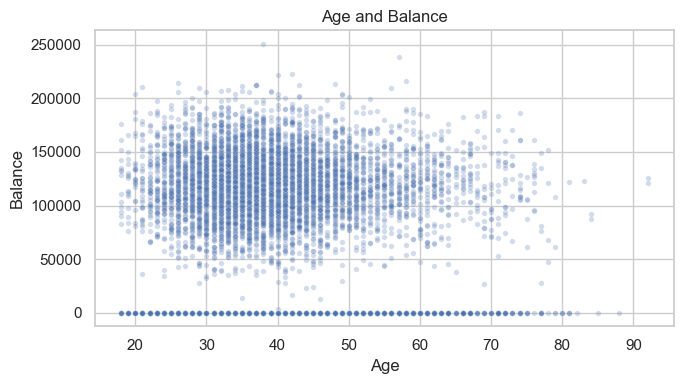

In [11]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="Age", y="Balance", alpha=0.25, s=15)
plt.title("Age and Balance")
plt.tight_layout()
plt.show()

In [12]:
print(f"Q1 = {q1:.2f}; Q3 = {q3:.2f}; IQR = {iqr:.2f}")
print(f"Lower bound = {lower:.2f}; upper bound = {upper:.2f}")
print(f"Outlier rows = {len(age_outliers)}")

Q1 = 32.00; Q3 = 44.00; IQR = 12.00
Lower bound = 14.00; upper bound = 62.00
Outlier rows = 359


In [13]:
print(f"Detected {len(age_outliers)} age outliers. First 10 rows:")
display(age_outliers.head(10))


Detected 359 age outliers. First 10 rows:


,RowNumber,Age
58,59,66
85,86,75
104,105,65
158,159,73
181,182,65
230,231,72
234,235,67
243,244,67
252,253,79
310,311,80


In [14]:
print(f"Pearson correlation of Age and Balance = {df['Age'].corr(df['Balance']):.3f}")

Pearson correlation of Age and Balance = 0.028


**Interpretation.** The IQR bounds are 14 and 62 years, so ages over 62 are flagged (359 customers). The scatter plot has no clear upward or downward pattern; the Age–Balance correlation is about 0.028, which also suggests almost no linear relationship.

### Task 2. Variable Transformation

I transform `Balance`. `log1p` means log(Balance + 1), so it also works for zero balances.

In [15]:
balance = df["Balance"]
log_balance = np.log1p(balance)
minmax_balance = (balance - balance.min()) / (balance.max() - balance.min())
z_balance = (balance - balance.mean()) / balance.std()

versions = {
    "Original": balance,
    "Log(Balance + 1)": log_balance,
    "Min-Max": minmax_balance,
    "Z-score": z_balance,
}
stats = pd.DataFrame({
    name: {"min": values.min(), "max": values.max(),
           "mean": values.mean(), "std": values.std()}
    for name, values in versions.items()
}).T
display(stats.round(3))

,min,max,mean,std
Original,0.000,250898.090,76485.889,62397.405
Log(Balance + 1),0.000,12.433,7.441,5.606
Min-Max,0.000,1.000,0.305,0.249
Z-score,-1.226,2.795,-0.000,1.000


**Interpretation.** For distances using several numeric features, I would use Z-score normalization for each feature. It puts features measured in different units on comparable scales, so a large balance does not automatically dominate age or tenure.

### Task 3. Distance and Similarity Measures

I use the same 10 sampled customers for all five measures. Numeric features are standardized before distance and cosine calculations. For Jaccard, each customer is a set of four category-value labels, such as `Geography=France` and `HasCrCard=1`.

In [16]:
sample = df.sample(n=10, random_state=42).sort_values("RowNumber")
row_ids = sample["RowNumber"].tolist()
scaler = StandardScaler()
all_scaled = scaler.fit_transform(df[num_cols])
X10 = all_scaled[sample.index]

matrices = {
    "Euclidean distance": pairwise_distances(X10, metric="euclidean"),
    "Manhattan distance": pairwise_distances(X10, metric="manhattan"),
    "Minkowski distance (p=3)": pairwise_distances(X10, metric="minkowski", p=3),
    "Cosine similarity": cosine_similarity(X10),
}

category_sets = []
for _, row in sample.iterrows():
    labels = set()
    for col in cat_cols:
        labels.add(f"{col}={row[col]}")
    category_sets.append(labels)

jaccard_matrix = np.zeros((10, 10))
for i in range(10):
    for j in range(10):
        intersection = len(category_sets[i] & category_sets[j])
        union = len(category_sets[i] | category_sets[j])
        jaccard_matrix[i, j] = intersection / union
matrices["Jaccard similarity"] = jaccard_matrix

**Euclidean distance matrix** (rows are RowNumbers)

In [17]:
display(pd.DataFrame(matrices['Euclidean distance'], index=row_ids, columns=row_ids).round(3))

,440,577,1732,4522,4685,4743,5203,6253,6341,6364
440,0.000,2.017,3.221,2.466,2.851,3.010,3.053,3.207,4.416,3.441
577,2.017,0.000,3.498,2.054,3.824,3.985,2.242,2.530,5.095,2.834
1732,3.221,3.498,0.000,3.436,1.862,3.518,3.245,1.980,2.946,2.756
4522,2.466,2.054,3.436,0.000,3.786,3.695,1.106,2.655,3.745,2.654
4685,2.851,3.824,1.862,3.786,0.000,3.671,3.797,2.714,3.029,3.585
4743,3.010,3.985,3.518,3.695,3.671,0.000,4.459,3.954,4.101,4.301
5203,3.053,2.242,3.245,1.106,3.797,4.459,0.000,2.280,3.741,2.246
6253,3.207,2.530,1.980,2.655,2.714,3.954,2.280,0.000,3.626,2.155
6341,4.416,5.095,2.946,3.745,3.029,4.101,3.741,3.626,0.000,3.867
6364,3.441,2.834,2.756,2.654,3.585,4.301,2.246,2.155,3.867,0.000


**Manhattan distance matrix** (rows are RowNumbers)

In [18]:
display(pd.DataFrame(matrices['Manhattan distance'], index=row_ids, columns=row_ids).round(3))

,440,577,1732,4522,4685,4743,5203,6253,6341,6364
440,0.000,3.603,6.882,5.296,5.833,6.155,6.202,6.342,8.927,5.766
577,3.603,0.000,7.409,4.013,8.819,8.684,4.314,4.609,11.065,5.011
1732,6.882,7.409,0.000,7.781,2.887,7.656,6.385,3.383,5.586,5.451
4522,5.296,4.013,7.781,0.000,8.526,6.743,2.349,5.672,8.006,5.382
4685,5.833,8.819,2.887,8.526,0.000,7.489,8.666,5.389,4.773,7.692
4743,6.155,8.684,7.656,6.743,7.489,0.000,8.904,7.836,7.316,9.459
5203,6.202,4.314,6.385,2.349,8.666,8.904,0.000,4.298,8.837,4.380
6253,6.342,4.609,3.383,5.672,5.389,7.836,4.298,0.000,7.634,4.388
6341,8.927,11.065,5.586,8.006,4.773,7.316,8.837,7.634,0.000,8.680
6364,5.766,5.011,5.451,5.382,7.692,9.459,4.380,4.388,8.680,0.000


**Minkowski distance (p=3) matrix** (rows are RowNumbers)

In [19]:
display(pd.DataFrame(matrices['Minkowski distance (p=3)'], index=row_ids, columns=row_ids).round(3))

,440,577,1732,4522,4685,4743,5203,6253,6341,6364
440,0.000,1.726,2.559,1.952,2.320,2.452,2.465,2.627,3.717,3.032
577,1.726,0.000,2.819,1.714,2.976,3.181,1.873,2.146,4.149,2.559
1732,2.559,2.819,0.000,2.692,1.674,2.754,2.667,1.742,2.431,2.296
4522,1.952,1.714,2.692,0.000,2.964,3.260,0.893,2.156,3.027,2.140
4685,2.320,2.976,1.674,2.964,0.000,2.983,2.920,2.240,2.693,2.883
4743,2.452,3.181,2.754,3.260,2.983,0.000,3.814,3.251,3.465,3.378
5203,2.465,1.873,2.667,0.893,2.920,3.814,0.000,1.930,2.852,1.895
6253,2.627,2.146,1.742,2.156,2.240,3.251,1.930,0.000,2.870,1.845
6341,3.717,4.149,2.431,3.027,2.693,3.465,2.852,2.870,0.000,3.025
6364,3.032,2.559,2.296,2.140,2.883,3.378,1.895,1.845,3.025,0.000


**Jaccard similarity matrix** (rows are RowNumbers)

In [20]:
display(pd.DataFrame(matrices['Jaccard similarity'], index=row_ids, columns=row_ids).round(3))

,440,577,1732,4522,4685,4743,5203,6253,6341,6364
440,1.000,0.333,0.333,0.600,0.333,0.600,0.600,0.143,0.333,0.333
577,0.333,1.000,1.000,0.600,0.143,0.143,0.600,0.143,0.333,1.000
1732,0.333,1.000,1.000,0.600,0.143,0.143,0.600,0.143,0.333,1.000
4522,0.600,0.600,0.600,1.000,0.333,0.333,0.333,0.000,0.600,0.600
4685,0.333,0.143,0.143,0.333,1.000,0.600,0.143,0.143,0.600,0.143
4743,0.600,0.143,0.143,0.333,0.600,1.000,0.333,0.333,0.600,0.143
5203,0.600,0.600,0.600,0.333,0.143,0.333,1.000,0.333,0.143,0.600
6253,0.143,0.143,0.143,0.000,0.143,0.333,0.333,1.000,0.143,0.143
6341,0.333,0.333,0.333,0.600,0.600,0.600,0.143,0.143,1.000,0.333
6364,0.333,1.000,1.000,0.600,0.143,0.143,0.600,0.143,0.333,1.000


**Cosine similarity matrix** (rows are RowNumbers)

In [21]:
display(pd.DataFrame(matrices['Cosine similarity'], index=row_ids, columns=row_ids).round(3))

,440,577,1732,4522,4685,4743,5203,6253,6341,6364
440,1.000,0.715,-0.075,0.432,0.286,0.442,0.129,-0.100,-0.565,-0.205
577,0.715,1.000,-0.121,0.676,-0.157,0.083,0.607,0.450,-0.888,0.307
1732,-0.075,-0.121,1.000,-0.591,0.592,0.046,-0.392,0.380,0.077,-0.116
4522,0.432,0.676,-0.591,1.000,-0.577,0.006,0.855,0.017,-0.380,0.080
4685,0.286,-0.157,0.592,-0.577,1.000,0.078,-0.561,0.080,0.169,-0.526
4743,0.442,0.083,0.046,0.006,0.078,1.000,-0.468,-0.280,-0.075,-0.465
5203,0.129,0.607,-0.392,0.855,-0.561,-0.468,1.000,0.293,-0.357,0.354
6253,-0.100,0.450,0.380,0.017,0.080,-0.280,0.293,1.000,-0.473,0.290
6341,-0.565,-0.888,0.077,-0.380,0.169,-0.075,-0.357,-0.473,1.000,-0.582
6364,-0.205,0.307,-0.116,0.080,-0.526,-0.465,0.354,0.290,-0.582,1.000


In [22]:
upper_i, upper_j = np.triu_indices(10, k=1)
descriptions = {
    "Euclidean distance": ("Straight-line distance; smaller is closer", "Six standardized numeric features"),
    "Manhattan distance": ("Sum of absolute differences; smaller is closer", "Six standardized numeric features"),
    "Minkowski distance (p=3)": ("Distance with power p=3; smaller is closer", "Six standardized numeric features"),
    "Jaccard similarity": ("Overlap of category-value sets; larger is closer", "Four categorical/binary features"),
    "Cosine similarity": ("Similarity of numeric vector directions; larger is closer", "Six standardized numeric features"),
}

comparison_rows = []
for name in ["Euclidean distance", "Manhattan distance", "Minkowski distance (p=3)",
             "Jaccard similarity", "Cosine similarity"]:
    matrix = matrices[name]
    candidate_scores = matrix[upper_i, upper_j]
    if "distance" in name:
        best_position = np.argmin(candidate_scores)
    else:
        best_position = np.argmax(candidate_scores)
    i = upper_i[best_position]
    j = upper_j[best_position]
    idea, computed_on = descriptions[name]
    comparison_rows.append({"Measure": name, "Main idea": idea, "Computed on": computed_on,
                            "Most similar pair (RowNumbers)": f"{row_ids[i]} and {row_ids[j]}",
                            "Score": candidate_scores[best_position]})

comparison = pd.DataFrame(comparison_rows)

**Comparison of the five measures**

In [23]:
display(comparison.round(3))

,Measure,Main idea,Computed on,Most similar pair (RowNumbers),Score
0,Euclidean distance,Straight-line distance; smaller is closer,Six standardized numeric features,4522 and 5203,1.106
1,Manhattan distance,Sum of absolute differences; smaller is closer,Six standardized numeric features,4522 and 5203,2.349
2,Minkowski distance (p=3),Distance with power p=3; smaller is closer,Six standardized numeric features,4522 and 5203,0.893
3,Jaccard similarity,Overlap of category-value sets; larger is closer,Four categorical/binary features,577 and 1732,1.000
4,Cosine similarity,Similarity of numeric vector directions; large...,Six standardized numeric features,4522 and 5203,0.855


**Interpretation.** The best pair can depend on the measure: distances compare numeric values, Jaccard compares categories, and cosine compares the directions of numeric vectors. The diagonal (a row compared with itself) is excluded when choosing a pair. If several pairs tie, the table shows the first one.

### Task 4. Correlation and Mutual Information

In [24]:
pearson = df[num_cols].corrwith(df[target])
mi = pd.Series(mutual_info_classif(df[num_cols], df[target], random_state=42), index=num_cols)

feature_scores = pd.DataFrame({"Pearson": pearson, "Absolute Pearson": pearson.abs(),
                               "Mutual Information": mi})
feature_scores["Pearson rank"] = feature_scores["Absolute Pearson"].rank(ascending=False, method="min").astype(int)
feature_scores["MI rank"] = feature_scores["Mutual Information"].rank(ascending=False, method="min").astype(int)

**Ranked by absolute Pearson correlation**

In [25]:
display(feature_scores.sort_values("Pearson rank").round(4))

,Pearson,Absolute Pearson,Mutual Information,Pearson rank,MI rank
Age,0.2853,0.2853,0.0692,1,2
Balance,0.1185,0.1185,0.0084,2,3
NumOfProducts,-0.0478,0.0478,0.0748,3,1
CreditScore,-0.0271,0.0271,0.0021,4,5
Tenure,-0.0140,0.0140,0.0000,5,6
EstimatedSalary,0.0121,0.0121,0.0027,6,4


**Ranked by Mutual Information**

In [26]:
display(feature_scores.sort_values("MI rank").round(4))

,Pearson,Absolute Pearson,Mutual Information,Pearson rank,MI rank
NumOfProducts,-0.0478,0.0478,0.0748,3,1
Age,0.2853,0.2853,0.0692,1,2
Balance,0.1185,0.1185,0.0084,2,3
EstimatedSalary,0.0121,0.0121,0.0027,6,4
CreditScore,-0.0271,0.0271,0.0021,4,5
Tenure,-0.0140,0.0140,0.0000,5,6


**Exit rate by number of products**

In [27]:
display(df.groupby("NumOfProducts")[target].agg(["count", "mean"]).rename(columns={"mean": "Exited rate"}).round(3))

,count,Exited rate
NumOfProducts,,
1,5084,0.277
2,4590,0.076
3,266,0.827
4,60,1.000


**Interpretation.** `NumOfProducts` is third by absolute Pearson correlation but first by Mutual Information. Its exit rate is low for two products, yet much higher for three or four. This pattern is not a simple straight line, so Pearson gives it a relatively low score while Mutual Information detects a stronger relationship.

## Part 2. Feature Selection, PCA, Kernel Functions, Outlier Analysis

### Task 5. Feature Selection

I one-hot encode the four categorical/binary features for Chi-square. I then use all six numeric features and the encoded categorical features for a Random Forest. The target is not included in the inputs.

In [28]:
encoded_cat = pd.get_dummies(df[cat_cols].astype(str), dtype=int)
chi_scores, p_values = chi2(encoded_cat, df[target])
chi_table = pd.DataFrame({"Chi-square": chi_scores, "p-value": p_values}, index=encoded_cat.columns)
chi_top5 = chi_table.sort_values("Chi-square", ascending=False).head(5)

X_features = pd.concat([df[num_cols], encoded_cat], axis=1)
forest = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1)
forest.fit(X_features, df[target])
importance = pd.Series(forest.feature_importances_, index=X_features.columns, name="Importance")
forest_top5 = importance.sort_values(ascending=False).head(5)
overlap = sorted(set(chi_top5.index) & set(forest_top5.index))

**Chi-square top 5**

In [29]:
display(chi_top5.round(4))

,Chi-square,p-value
Geography_Germany,225.4644,0.0
IsActiveMember_0,125.5610,0.0
IsActiveMember_1,118.1994,0.0
Gender_Female,61.9092,0.0
Geography_France,54.9237,0.0


**Random Forest top 5**

In [30]:
display(forest_top5.to_frame().round(4))

,Importance
Age,0.3799
NumOfProducts,0.3052
IsActiveMember_1,0.0646
Geography_Germany,0.0642
Balance,0.0543


In [31]:
print("Features in both top-5 lists:", overlap)

Features in both top-5 lists: ['Geography_Germany', 'IsActiveMember_1']


**Interpretation.** `Geography_Germany` and `IsActiveMember_1` appear in both top-five lists. Chi-square checks association with the target for encoded categories; Random Forest measures how useful features are for its splits. The rankings therefore do not have to be identical.

### Task 6. PCA

In [32]:
scaled_numeric = StandardScaler().fit_transform(df[num_cols])
pca = PCA()
pca.fit(scaled_numeric)
ratios = pca.explained_variance_ratio_
cumulative = np.cumsum(ratios)
pca_table = pd.DataFrame({"Component": np.arange(1, len(ratios) + 1),
                          "Explained variance ratio": ratios,
                          "Cumulative variance": cumulative})
minimum_components = int(np.searchsorted(cumulative, 0.8) + 1)

In [33]:
display(pca_table.round(4))

,Component,Explained variance ratio,Cumulative variance
0,1,0.2185,0.2185
1,2,0.1689,0.3874
2,3,0.1669,0.5543
3,4,0.1654,0.7197
4,5,0.1647,0.8843
5,6,0.1157,1.0000


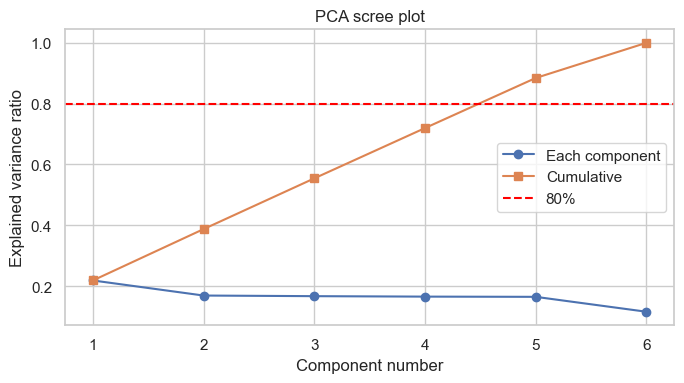

In [34]:
plt.figure(figsize=(7, 4))
plt.plot(pca_table["Component"], ratios, marker="o", label="Each component")
plt.plot(pca_table["Component"], cumulative, marker="s", label="Cumulative")
plt.axhline(0.8, color="red", linestyle="--", label="80%")
plt.xticks(pca_table["Component"])
plt.xlabel("Component number")
plt.ylabel("Explained variance ratio")
plt.title("PCA scree plot")
plt.legend()
plt.tight_layout()
plt.show()

In [35]:
print("Minimum components for at least 80% variance:", minimum_components)
print(f"Variance retained: {cumulative[minimum_components - 1]:.2%}")

Minimum components for at least 80% variance: 5
Variance retained: 88.43%


**Interpretation.** Five components are needed to keep at least 80% of the total variance (about 88.4%). Four components keep about 72.0%, which is below the requested threshold.

### Task 7. Kernel Functions

I use the same 10 customers and standardized numeric features as in Task 3. For RBF, γ = 0.5.

In [36]:
gamma = 0.5
K_linear = linear_kernel(X10)
K_rbf = rbf_kernel(X10, gamma=gamma)

**Linear kernel matrix**

In [37]:
display(pd.DataFrame(K_linear, index=row_ids, columns=row_ids).round(4))

,440,577,1732,4522,4685,4743,5203,6253,6341,6364
440,6.3871,5.0207,-0.3459,2.2236,1.6086,3.4600,0.6757,-0.4375,-3.5199,-0.9713
577,5.0207,7.7219,-0.6104,3.8233,-0.9717,0.7172,3.4902,2.1730,-6.0829,1.5989
1732,-0.3459,-0.6104,3.2964,-2.1835,2.3941,0.2594,-1.4742,1.2005,0.3457,-0.3944
4522,2.2236,3.8233,-2.1835,4.1415,-2.6140,0.0406,3.6003,0.0592,-1.9056,0.3041
4685,1.6086,-0.9717,2.3941,-2.6140,4.9606,0.5395,-2.5854,0.3088,0.9301,-2.1927
4743,3.4600,0.7172,0.2594,0.0406,0.5395,9.5953,-3.0012,-1.5092,-0.5749,-2.6991
5203,0.6757,3.4902,-1.4742,3.6003,-2.5854,-3.0012,4.2831,1.0548,-1.8202,1.3742
6253,-0.4375,2.1730,1.2005,0.0592,0.3088,-1.5092,1.0548,3.0236,-2.0266,0.9445
6341,-3.5199,-6.0829,0.3457,-1.9056,0.9301,-0.5749,-1.8202,-2.0266,6.0739,-2.6847
6364,-0.9713,1.5989,-0.3944,0.3041,-2.1927,-2.6991,1.3742,0.9445,-2.6847,3.5093


**RBF kernel matrix**

In [38]:
display(pd.DataFrame(K_rbf, index=row_ids, columns=row_ids).round(6))

,440,577,1732,4522,4685,4743,5203,6253,6341,6364
440,1.000000,0.130831,0.005585,0.047801,0.017158,0.010767,0.009471,0.005841,0.000058,0.002686
577,0.130831,1.000000,0.002199,0.121425,0.000667,0.000356,0.081079,0.040770,0.000002,0.018011
1732,0.005585,0.002199,1.000000,0.002733,0.176497,0.002057,0.005175,0.140929,0.013044,0.022433
4522,0.047801,0.121425,0.002733,1.000000,0.000773,0.001083,0.542253,0.029499,0.000900,0.029561
4685,0.017158,0.000667,0.176497,0.000773,1.000000,0.001184,0.000741,0.025139,0.010182,0.001616
4743,0.010767,0.000356,0.002057,0.001083,0.001184,1.000000,0.000048,0.000402,0.000223,0.000096
5203,0.009471,0.081079,0.005175,0.542253,0.000741,0.000048,1.000000,0.074378,0.000913,0.080299
6253,0.005841,0.040770,0.140929,0.029499,0.025139,0.000402,0.074378,1.000000,0.001394,0.098081
6341,0.000058,0.000002,0.013044,0.000900,0.010182,0.000223,0.000913,0.001394,1.000000,0.000566
6364,0.002686,0.018011,0.022433,0.029561,0.001616,0.000096,0.080299,0.098081,0.000566,1.000000


In [39]:
distance_matrix = pairwise_distances(X10, metric="euclidean")
pair_scores = distance_matrix[upper_i, upper_j]
farthest_position = np.argmax(pair_scores)
i = upper_i[farthest_position]
j = upper_j[farthest_position]

In [40]:
print(f"Most different pair (RowNumbers): {row_ids[i]} and {row_ids[j]}")
print(f"Euclidean distance = {distance_matrix[i, j]:.4f}")
print(f"Linear kernel = {K_linear[i, j]:.4f}")
print(f"RBF kernel = {K_rbf[i, j]:.8f}")

Most different pair (RowNumbers): 577 and 6341
Euclidean distance = 5.0953
Linear kernel = -6.0829
RBF kernel = 0.00000230


**Interpretation.** Rows 577 and 6341 are the most different pair in this sample by Euclidean distance. Their linear score is negative (about −6.08) because their standardized feature vectors point in different directions. RBF uses the squared distance and gives a value near zero (about 0.0000023), indicating very low similarity; the two formulas produce scores on different scales.

### Task 8. Outlier Analysis

I compare the Z-score rule `|Z| > 3` with the IQR rule from Task 1 for `Age`.

In [41]:
age_z = (age - age.mean()) / age.std()
z_indices = set(df.index[age_z.abs() > 3])
iqr_indices = set(age_outliers.index)
only_one = sorted(iqr_indices.symmetric_difference(z_indices))
global_index = age.idxmax()
global_row = df.loc[global_index]

In [42]:
print("Z-score outlier count:", len(z_indices))
print("IQR outlier count:", len(iqr_indices))

Z-score outlier count: 133
IQR outlier count: 359


In [43]:
if only_one:
    example_index = only_one[0]
    row = df.loc[example_index]
    method = "IQR only" if example_index in iqr_indices else "Z-score only"
    print(f"Row found by one method: RowNumber={int(row['RowNumber'])}, "
          f"Age={int(row['Age'])}, Z={age_z.loc[example_index]:.3f}, method={method}")

Row found by one method: RowNumber=59, Age=66, Z=2.582, method=IQR only


In [44]:
print(f"Global outlier example: RowNumber={int(global_row['RowNumber'])}, "
      f"Age={int(global_row['Age'])}, Z={age_z.loc[global_index]:.3f}")
print("Flagged by IQR:", global_index in iqr_indices)
print("Flagged by Z-score:", global_index in z_indices)

Global outlier example: RowNumber=6444, Age=92, Z=5.061
Flagged by IQR: True
Flagged by Z-score: True


**Interpretation.** IQR flags 359 ages, while Z-score flags 133. The printed example is an age flagged by IQR but not Z-score because the rules use different cutoffs. The customer aged 92 is a **global outlier**: this age is unusually high compared with the whole age distribution, without needing a special subgroup or a group of rows to make it unusual.

## 4. Baseline Churn Prediction

The earlier sections explore the data and several data-mining methods. I now add a small supervised-learning step to connect the analysis with the business problem.

I compare two common baselines:
- **Logistic Regression** — a simple, interpretable linear model.
- **Random Forest** — a tree-based model that can capture non-linear patterns.

I use a stratified 80/20 train/test split. Numeric features are scaled, categorical features are one-hot encoded, and preprocessing is fitted only on the training data through a `Pipeline`.


In [45]:
# Use only the 10 selected customer features; exclude identifiers and the target.
feature_cols = num_cols + cat_cols
X = df[feature_cols].copy()
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

def make_preprocessor():
    """Create an independent preprocessing transformer for each model."""
    return ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), num_cols),
            ("categorical", OneHotEncoder(handle_unknown="ignore"), cat_cols)
        ]
    )

models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print(f"Churn share in test set: {y_test.mean():.1%}")


Training rows: 8000
Test rows: 2000
Churn share in test set: 20.3%


### Model comparison

I report Accuracy, Precision, Recall, F1-score, and ROC-AUC. Since the target classes are not equally represented, I do not rely on Accuracy alone. The default classification threshold is 0.5; threshold tuning is outside the scope of this compact baseline.


In [46]:
evaluation_rows = []

for model_name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    evaluation_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

model_results = (
    pd.DataFrame(evaluation_rows)
      .sort_values("ROC-AUC", ascending=False)
      .reset_index(drop=True)
)
display(model_results.set_index("Model").style.format("{:.3f}"))

best_model_name = model_results.loc[0, "Model"]
best_model = models[best_model_name]
best_predictions = best_model.predict(X_test)
print(f"Best baseline by ROC-AUC: {best_model_name}")


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Random Forest,0.842,0.607,0.629,0.618,0.855
Logistic Regression,0.714,0.387,0.700,0.499,0.777


Best baseline by ROC-AUC: Random Forest


### Confusion matrix and error analysis

The confusion matrix helps distinguish two types of mistakes: customers predicted to leave who actually stay (false positives), and customers predicted to stay who actually leave (false negatives). In a retention use case, the preferred balance depends on the cost of contacting customers versus the cost of losing them.


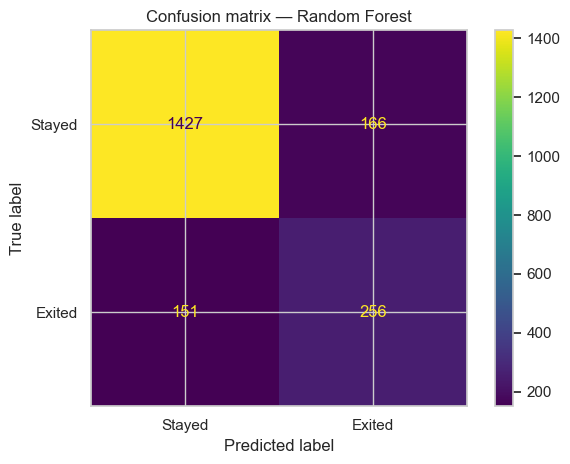

              precision    recall  f1-score   support

      Stayed       0.90      0.90      0.90      1593
      Exited       0.61      0.63      0.62       407

    accuracy                           0.84      2000
   macro avg       0.76      0.76      0.76      2000
weighted avg       0.84      0.84      0.84      2000



In [47]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=["Stayed", "Exited"],
    values_format="d"
)
plt.title(f"Confusion matrix — {best_model_name}")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    best_predictions,
    target_names=["Stayed", "Exited"],
    zero_division=0
))


### Modelling takeaway

Compare the two models using the test-set metrics above. Recall for the `Exited` class indicates how many actual churners the model identifies; Precision indicates how many customers flagged by the model really churned. A bank would choose a probability threshold based on retention-team capacity and the relative costs of false positives and false negatives.

**Limitations**
- This is a public, cross-sectional dataset; it does not provide a time-based validation setup.
- The results describe predictive association, not causal drivers of churn.
- No campaign exposure or offer-response data is available, so this project does not estimate the incremental effect of a retention offer and does not implement Next Best Offer.
- The baseline models are a starting point, not a production-ready system.


## 5. Conclusion

This project combines customer-level exploratory analysis with a compact churn-classification baseline. The data-mining sections demonstrate how scaling, similarity measures, correlation, Mutual Information, Chi-square, Random Forest feature importance, PCA, kernel functions, and outlier methods can be applied to customer data.

The final model comparison provides an initial estimate of how well simple classifiers separate customers who leave from those who stay. The most useful next improvement would be to validate the model on more recent customer data and select a decision threshold using realistic retention costs and campaign capacity.
